# MonoLM-346M: подготовка к обучению

Реализован pretrain с нуля: **Transformers + Accelerate + Flash Attention 4 + локальный Trackio**. Полное обучение не запущено. Здесь сохранены результаты подготовки корпуса, функциональных проверок и ограниченных замеров GPU. Проверочные веса не используются для финального запуска.

Цель будущего запуска — максимум одна эпоха и сутки на RTX 5080. Test остаётся закрытым. Метрики коротких проверок не доказывают качество генерации.

Код вынесен в пакет `src`; установите его через `bash scripts/setup.sh l40` (или профиль `5080`). Сохранённые результаты относятся к прежнему запуску. Пути берутся из `src.paths` и учитывают `MONOLM_ARTIFACTS`. Команды воспроизведения — в `task1/README.md`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.paths import TASK as ROOT, ARTIFACTS
A = ARTIFACTS / "training"
def read(path):
    return json.loads(path.read_text())
config = read(A / "recommended_config.json")
functional = read(A / "checks/functional.json")
display(pd.Series(functional["versions"], name="Версия").to_frame())

,Версия
torch,2.14.1
transformers,5.20.2
accelerate,1.15.0
flash-attn-4,4.0.0b36
trackio,0.43.0
tokenizers,0.23.3
numpy,2.5.4


## Архитектура и память

`Qwen3ForCausalLM` создаётся из нашего конфига со случайной инициализацией, без загрузки готовых весов. 32 слоя, hidden 960, FFN 2560, GQA 15/5, head dimension 64, SwiGLU, RMSNorm + QK-Norm, RoPE theta 10000, контекст 2048. Словарь — наш BPE-32768; embedding и выходная матрица связаны. Bias и dropout отключены.

BF16 autocast относится к вычислениям. Веса, градиенты и два момента AdamW имеют FP32. Поэтому постоянные тензоры занимают примерно `16 × P` байт; активации, временные тензоры, CUDA и кеш аллокатора требуют дополнительной памяти. Чекпоинт на границе шага не содержит градиенты.

In [2]:
params = pd.DataFrame(read(A / "parameters.json"))
display(pd.Series(config["model"], name="Значение").to_frame())
total = int(params.parameters.sum())
print(f"Параметров: {total:,}; веса + градиенты + AdamW: {16 * total / 2**30:.3f} ГиБ")
display(params[params.module.isin(["embedding / output", "layer 3", "final norm"])].set_index("module"))
assert total == 346096576

,Значение
vocab_size,32768
hidden_size,960
intermediate_size,2560
num_hidden_layers,32
num_attention_heads,15
num_key_value_heads,5
head_dim,64
max_position_embeddings,2048


Параметров: 346,096,576; веса + градиенты + AdamW: 5.157 ГиБ


,parameters,weights_fp32_bytes,gradients_fp32_bytes,adam_moments_fp32_bytes,weights_bf16_bytes
module,,,,,
embedding / output,31457280,125829120,125829120,251658240,62914560
layer 3,9832448,39329792,39329792,78659584,19664896
final norm,960,3840,3840,7680,1920


## Данные и next-token prediction

Все train/validation документы закодированы без обрезания. К каждому добавлен один EOS ID 3; BOS не добавляется. Литералы `[EOS]` и другие служебные строки внутри текста остаются обычным текстом.

Поток хранится как uint16. Для блока с началом `s` вход — `tokens[s:s+2048]`, цель — `tokens[s+1:s+2049]`: сдвиг выполняется один раз. Последний неполный блок дополняется PAD с игнорируемыми целями. Длинные документы продолжаются в следующих блоках. Attention может переходить через EOS, позиции начинаются с нуля в каждом блоке.

Порядок train-блоков — фиксированная перестановка, seed 42. Прежняя Top-dev выборка служила только для сравнения токенизаторов и остаётся частью train для LLM. Validation — отдельные 5000 документов официального распределения.

In [3]:
data = read(A / "data/manifest.json")
rows = [{"split": split, "documents": value["documents"], "content_tokens": value["content_tokens"],
         "with_EOS": value["tokens"], "targets": value["targets"], **value["document_lengths"]}
        for split, value in data["splits"].items()]
display(pd.DataFrame(rows).set_index("split"))
assert read(A / "data_verification.json")["verified"]
print("Квантили относятся к длине документа без EOS; количество токенов рассчитано на всём корпусе.")

,documents,content_tokens,with_EOS,targets,min,p50,p90,p95,p99,max
split,,,,,,,,,,
train,1000000,1203544281,1204544281,1204544280,55.0,611.0,2222.0,3699.0,11979.01,151239.0
validation,5000,3802660,3807660,3807659,65.0,397.0,1476.0,2252.4,7070.83,29097.0


Квантили относятся к длине документа без EOS; количество токенов рассчитано на всём корпусе.


## Проверки работоспособности

Проверены точное восстановление маленького CPU-прогона, optimizer/scheduler/RNG, причинность attention, последний неполный блок, экспорт и обратимость токенизатора. На полной модели проверены BF16 forward/backward, сохранение/загрузка состояния и следующий шаг оптимизатора. GPU-числа могут иметь небольшие различия из-за недетерминированных kernels.

In [4]:
display(pd.Series({k: v for k, v in functional.items() if k != "versions"}, name="Результат").to_frame())
display(pd.Series(read(A / "checks/gpu.json"), name="GPU").to_frame())
display(pd.Series(read(A / "checks/inference.json"), name="Инференс").to_frame())
display(pd.Series(read(A / "gpu_check_budget.json"), name="Бюджет проверок").to_frame())

,Результат
cpu_resume_exact,True
rng_restored,True
optimizer_restored,True
scheduler_restored,True
causal,True
padding_excluded,True
export_roundtrip,True
tokenizer_roundtrip,True
trackio_logged,True
parameters,346096576


,GPU
checkpoint_loss_before,10.013449
checkpoint_loss_after,10.013449
resumed_loss,9.249458
attention,flash_attention_4
device,NVIDIA GeForce RTX 5080
bf16,True
full_loop_resume,True
separate_processes,True
steps,2
tokens,262144


,Инференс
full_model_export_loaded,True
tied_weights,True
prompts,1
max_new_tokens,16
generated_tokens,16
flash_attention_kv_cache,True


,Бюджет проверок
limit_seconds,900
used_seconds,505.978372
note,Conservative 220 s for initial FA4 probes and ...


## Скорость полной модели

В каждой конфигурации один прогревочный и два измеряемых optimizer steps. Каждый шаг включает 131072 токена, накопление градиентов, backward, clipping и AdamW. Время первого запуска показано отдельно; JIT-компиляция Flash Attention может замедлить прогрев.

Выбираем быстрый вариант с запасом свободной VRAM не менее 1 ГиБ и успешной проверкой resume. Микробатч 4 дал OOM при повторном запуске после загрузки состояния; микробатч 2 сохранил 99,4% его скорости и больший запас памяти. В повторных запусках одного процесса OOM возникал также с микробатчем 2. Исправлена очистка ссылок после Accelerate, включён `expandable_segments:True`; фактический resume проверен в отдельном процессе. Его первый шаг включает холодный запуск kernels и не заменяет замер установившейся скорости. Измерения выполнены на небольшом повторяемом наборе блоков и дают ориентир, а не гарантию скорости суточного запуска.

,microbatch,activation_checkpointing,compile,warmup_seconds,status,step_seconds,tokens_per_second,loss,peak_allocated_gib,peak_reserved_gib,free_gib,resume_valid,resume_note
0,1,False,False,12.839384,ok,10.361576,12649.813100,9.265101,10.596981,10.761719,3.428284,NaN,NaN
1,2,False,False,8.886798,ok,7.750851,16910.658918,8.641966,15.307865,15.822266,0.000000,NaN,NaN
2,4,False,False,NaN,out_of_memory,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,True,False,16.536433,ok,14.938363,8774.187536,8.133565,6.623440,7.447266,7.081055,NaN,NaN
4,2,True,False,8.695909,ok,8.231568,15923.090971,7.850735,7.838902,9.025391,5.502930,NaN,NaN
5,4,True,False,8.142492,ok,8.180885,16021.739034,7.728125,10.370686,11.347656,2.864906,False,OOM during second in-process run after checkpo...


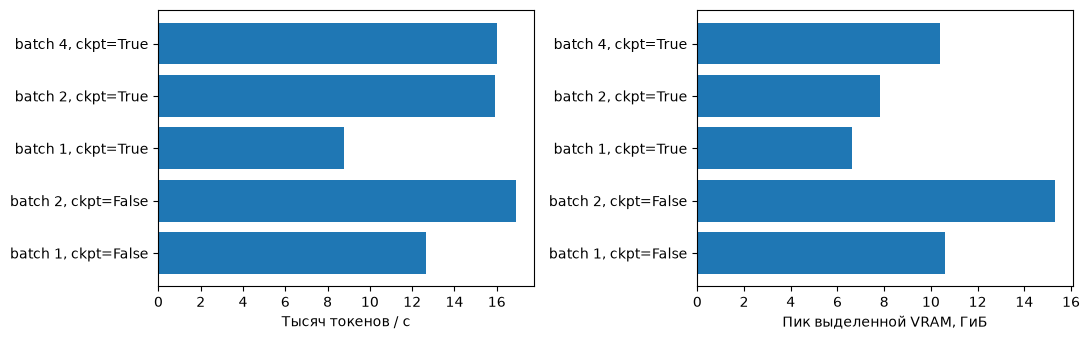

In [5]:
bench = pd.DataFrame(read(A / "benchmark.json"))
display(bench)
ok = bench[bench.status == "ok"].copy()
ok["label"] = ok.apply(lambda r: f"batch {r.microbatch}, ckpt={r.activation_checkpointing}", axis=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].barh(ok.label, ok.tokens_per_second / 1000)
axes[0].set_xlabel("Тысяч токенов / с")
axes[1].barh(ok.label, ok.peak_allocated_gib)
axes[1].set_xlabel("Пик выделенной VRAM, ГиБ")
fig.tight_layout()
(A / "figures").mkdir(exist_ok=True)
fig.savefig(A / "figures/benchmark.png", dpi=150)
plt.show()

## Настройки будущего запуска

Fused AdamW: betas (0.9, 0.95), eps 1e-8. Weight decay 0.1 для матриц; нормализации без decay. Пик LR 3e-4, минимум 3e-5, warmup 2% шагов, затем cosine; clipping 1.0. Эффективный batch 131072 токена. Суммы loss по микробатчам делятся на фактическое число целей во всём optimizer step.

План шагов — минимум из одной эпохи и 90% суточного бюджета по измеренной скорости. Есть дополнительный таймер с резервом на сохранение. Resume сохраняет исходный scheduler и накопленное время.

Trackio и JSONL: train loss, LR, norm до clipping, скорость, токены, время, память. Фиксированные 128 validation-блоков оцениваются до запуска, каждые 250 шагов и в конце; полный validation — при штатном завершении. Генерация шести фиксированных продолжений каждые 1000 шагов не изменяет RNG обучения.

Чекпоинты сохраняются каждые 15 минут и при улучшении validation loss. Запись атомарная, с контрольными суммами. Хранятся два последних и лучший; последний содержит финальное состояние при завершении. При возобновлении новая попытка Trackio входит в ту же группу.

In [6]:
budget = read(A / "budget.json")
display(pd.Series(config["runtime"], name="Выбранное исполнение").to_frame())
display(pd.Series({k: v for k, v in budget.items() if k != "selected"}, name="План").to_frame())
content = data["splits"]["train"]["tokens"]
planned = min(content - 1, config["training"]["planned_steps"] * config["training"]["batch_tokens"])
display(Markdown(f"**Точный корпус:** {content:,} токенов с EOS. "
                 f"**План:** {config['training']['planned_steps']:,} шагов, около {planned:,} предсказываемых токенов. "
                 f"Чистое обучение по замеру: {budget['estimated_training_hours']:.2f} ч; "
                 f"полная эпоха: {budget['estimated_epoch_hours']:.2f} ч. "
                 "Остальное время оставлено на валидацию, запись и колебания производительности. "
                 "Качество обученной LLM на этом этапе ещё не оценено."))

,Выбранное исполнение
attention,flash_attention_4
microbatch,2
activation_checkpointing,True
compile,False
cpu_threads,8


,План
epoch_steps,9190
planned_steps,9190
estimated_training_hours,21.013363
estimated_epoch_hours,21.013363
compile,Not measured; eager Flash Attention selected w...
selection_reason,Microbatch 2 has 99.4% of batch-4 throughput a...


**Точный корпус:** 1,204,544,281 токенов с EOS. **План:** 9,190 шагов, около 1,204,544,280 предсказываемых токенов. Чистое обучение по замеру: 21.01 ч; полная эпоха: 21.01 ч. Остальное время оставлено на валидацию, запись и колебания производительности. Качество обученной LLM на этом этапе ещё не оценено.

## Команды из каталога `task1`

Подготовка и проверки уже выполнены; повторный `prepare` проверяет готовые файлы. `benchmark` расходует общий ограниченный бюджет GPU-проверок.

```bash
../venv/bin/python -m src tokenize
../venv/bin/python -m src check --config configs/train_5080.json
../venv/bin/python -m src benchmark --config configs/train_5080.json
```

**Будущее финальное обучение — команда приведена для отдельного запуска, здесь не выполняется:**

```bash
bash scripts/train.sh
```

Возобновление той же директории:

```bash
bash scripts/train.sh --resume artifacts/training/runs/monolm-346m/checkpoints/last.json
```

Локальный dashboard:

```bash
TRACKIO_DIR="$PWD/artifacts/training/trackio" ../venv/bin/trackio show --project monolm
```

Экспорт лучшего чекпоинта:

```bash
../venv/bin/python -m src export --resume artifacts/training/runs/monolm-346m/checkpoints/best.json --run artifacts/training/export-best
```

Совместимость проверена на установленных версиях, включая `flash-attn-4==4.0.0b36` (beta). Источники: [Accelerate](https://huggingface.co/docs/accelerate/main/en/basic_tutorials/migration), [Flash Attention](https://github.com/Dao-AILab/flash-attention), [Trackio](https://huggingface.co/docs/trackio/track).